In [33]:
import matplotlib.pyplot as plt
from dstools.dynamic_spectrum import DynamicSpectrum, LightCurve
from dstools.plotting import plot_ds, plot_lightcurve
import os
from pathlib import Path
import numpy as np
from astropy.io import fits
from astropy.wcs import WCS
from matplotlib.patches import Rectangle
import astropy.constants as c
import astropy.units as u
from scipy.optimize import curve_fit
from scipy.optimize import brentq
import lightkurve as lk
from astropy.timeseries import LombScargle
from astropy.time import Time
from matplotlib.ticker import MaxNLocator
from astropy.coordinates import SkyCoord, EarthLocation
from astropy.table import Table
import astropy.units as u
import re
from astroquery.gaia import Gaia
from astroquery.simbad import Simbad
from collections import Counter

# Solar burst rates

To start, adapt the work from Nita 2002 to get the rates of solar flares above a certain sfu

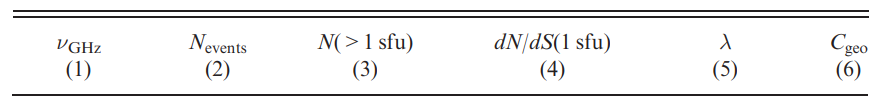

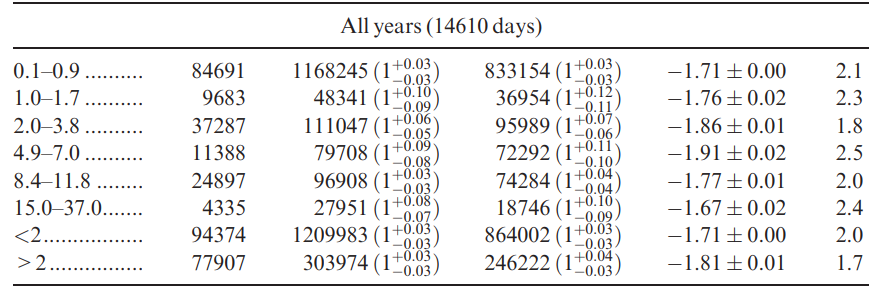

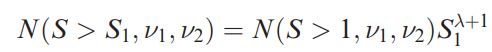

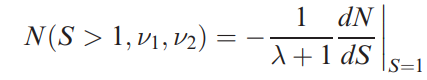

From the above, we can write a function to calculate the number of expected flares (per day) at a given SFU and frequency. As such, we just need to calculate an equivelant SFU for each of our stellar dynamic spectra.

# Estimating maximum flare luminosity of our stars

First, let's load in our data, find a way to query our dynamic spectra, and see if we can find a distance to each of these stars again.

In [34]:
vis_path = Path('../visibility_files/')
ds_files = list(vis_path.rglob('*.ds'))

In [35]:
sources = Table.read('data/source_obs_data.csv')

In [36]:
srsc_id_table = Table.read('data/2026.01.16_12_07_51_SRSC_Static.csv')

In [37]:
dist_data = Table.read('data/gaia_bj_data.csv')

In [38]:
dist_data

source_id,phot_g_mean_mag,bp_rp,teff_gspphot,logg_gspphot,r_med_geo,r_lo_geo,r_hi_geo,abs_mag
int64,float64,float64,float64,float64,float64,float64,float64,float64
2162964329341318656,7.026026725769043,1.008195400238037,5043.0107421875,2.925299882888794,112.16966247558594,111.99203491210938,112.31864166259766,1.7766494750976562
2498548845936384000,9.362846374511719,1.0621395111083984,4920.13525390625,4.247700214385986,68.96206665039062,68.87015533447266,69.05001831054688,5.169795036315918
2671331703762455552,9.138297080993652,0.78265380859375,5750.85888671875,4.391200065612793,79.15748596191406,79.01716613769531,79.2906265258789,4.64583683013916
2844189676273462400,9.229718208312988,1.1572704315185547,6001.25537109375,3.6182000637054443,162.2353973388672,161.75747680664062,162.6252899169922,3.1789894104003906
2953124752872327296,9.517234802246094,0.9739837646484375,5376.81689453125,3.6677000522613525,158.03216552734375,157.37733459472656,158.65728759765625,3.5235071182250977
4112215960860030592,6.63777494430542,-0.10967493057250977,11727.0322265625,4.110400199890137,144.96524047851562,144.04342651367188,146.03128051757812,0.8314547538757324
4621305817457618176,8.91532039642334,0.9902505874633789,5109.96484375,4.318699836730957,58.80509948730469,58.75656509399414,58.84265899658203,5.068244934082031
4730672387943135616,12.846132278442383,2.8343868255615234,3000.5771484375,4.166900157928467,29.560894012451172,29.5412540435791,29.579771041870117,10.492544174194336
4743944043046490240,8.516792297363281,0.8914098739624023,5543.96435546875,4.424200057983398,49.56941223144531,49.53261184692383,49.608699798583984,5.04072380065918


In [39]:
srsc_id_table

Identifier,Simbad_ID,GaiaDR3_ID,TYCHO_ID,2MASS_ID,GCVS_ID,HIP_ID,UCAC4_ID,Archival_Survey,Archival_ID,Archival_epoch,Archival_ra,Archival_ra_err,Archival_dec,Archival_dec_err,Archival_ra_hms,Archival_dec_dms,Archival_parallax,Archival_parallax_err,Archival_pmra,Archival_pmra_err,Archival_pmdec,Archival_pmdec_err,Radio_multiple,Search_method_bin,1RXS_ID,TIC_ID,WISE_ID,AllWISE_ID,CNS5_ID,Stripped_Identifier,Stripped_Archival_ID
str10,str31,str28,str15,str23,str14,str10,str16,str39,str28,str19,float64,float64,float64,float64,str17,str19,float64,float64,float64,float64,float64,float64,float64,int64,str21,str14,str25,str25,str9,str9,str26
SRSC 00000,CPD-62 4126,Gaia DR3 5853502492753436416,TYC 9010-2749-1,2MASS J14270430-6246553,--,--,UCAC4 137-115021,GaiaDR3,Gaia DR3 5853502492753436416,J2016,216.767919155244,6e-06,-62.782098179545,9e-06,14:27:04,-62:46:55.553446362,1.53,0.01,-3.841,0.007,-5.44,0.01,0.0,18,1RXS J142704.5-624659,TIC 385279385,--,--,--,SRSC00000,GaiaDR35853502492753436416
SRSC 00001,TYC 9078-815-1,Gaia DR3 6438561254116213760,TYC 9078-815-1,2MASS J19040331-6400142,--,--,UCAC4 130-173182,GaiaDR3,Gaia DR3 6438561254116213760,J2016,286.013875552226,8e-06,-64.00397308781,9e-06,19:04:03,-64:00:14.303116116,2.38,0.01,6.74,0.01,-4.68,0.01,0.0,18,1RXS J190403.3-640011,--,--,--,--,SRSC00001,GaiaDR36438561254116213760
SRSC 00002,SCR J2241-6119A,Gaia DR3 6406967509044836096,--,2MASS J22414436-6119311,--,--,UCAC4 144-211738,GaiaDR3,Gaia DR3 6406967509044836096,J2016,340.436272395047,8e-06,-61.325706059717,1e-05,22:41:45,-61:19:32.541814980,35.2,0.01,150.4,0.01,-87.89,0.01,0.0,18,--,TIC 232064182,WISE J224144.56-611932.0,--,--,SRSC00002,GaiaDR36406967509044836096
SRSC 00003,CD-30 6530,Gaia DR3 5640708647248169600,TYC 7136-2264-1,2MASS J08355977-3042306,--,--,UCAC4 297-048519,GaiaDR3,Gaia DR3 5640708647248169600,J2016,128.998712548091,8e-06,-30.70858670455,1e-05,08:36:00,-30:42:30.91213638,15.7,0.01,-64.11,0.01,-14.3,0.01,0.0,18,1RXS J083559.7-304226,TIC 11663272,--,--,--,SRSC00003,GaiaDR35640708647248169600
SRSC 00004,CD-49 451,Gaia DR3 4917782741272766592,TYC 8043-814-1,2MASS J01372081-4911443,--,HIP 7554,UCAC4 205-001600,GaiaDR3,Gaia DR3 4917782741272766592,J2016,24.34012397651,1e-05,-49.195143947004,1e-05,01:37:22,-49:11:42.51820921,45.12,0.01,496.1,0.01,116.1,0.01,0.0,18,1RXS J013721.1-491144,TIC 158624542,--,WISEA J013721.34-491143.1,CNS5 406,SRSC00004,GaiaDR34917782741272766592
SRSC 00005,ATO J183.5330+47.2673,Gaia DR3 1545247048904161664,--,2MASS J12140814+4716038,--,--,UCAC4 687-053931,GaiaDR3,Gaia DR3 1545247048904161664,J2016,183.532979271787,1e-05,47.267364915243,1e-05,12:14:08,+47:16:02.51369487,25.76,0.02,-137.2,0.01,-72.58,0.01,0.0,16,--,TIC 138182259,--,WISEA J121407.98+471602.9,--,SRSC00005,GaiaDR31545247048904161664
SRSC 00006,HD 102982,Gaia DR3 5368777294028600448,TYC 8228-2739-1,2MASS J11510909-5152323,--,--,UCAC4 191-064625,GaiaDR3,Gaia DR3 5368777294028600448,J2016,177.787504285457,1e-05,-51.876071495961,1e-05,11:51:09,-51:52:33.85738546,18.8,0.02,-57.34,0.02,-83.67,0.01,0.0,18,1RXS J115108.5-515223,TIC 94637805,--,--,--,SRSC00006,GaiaDR35368777294028600448
SRSC 00007,2MASS J11414215-6521298,Gaia DR3 5236539580341818624,--,2MASS J11414215-6521298,--,--,UCAC4 124-048667,GaiaDR3,Gaia DR3 5236539580341818624,J2016,175.425221260026,1e-05,-65.358320600806,1e-05,11:41:42,-65:21:29.95416290,9.92,0.02,-40.18,0.02,-4.38,0.02,0.0,18,1RXS J114142.1-652128,TIC 321772880,--,--,--,SRSC00007,GaiaDR35236539580341818624
SRSC 00008,Gaia DR3 6090676737160646528,Gaia DR3 6090676737160646528,--,--,--,--,--,GaiaDR3,Gaia DR3 6090676737160646528,J2016,211.790382522137,1e-05,-50.034311567705,1e-05,14:07:10,-50:02:03.52164374,10.99,0.02,-54.59,0.02,-46.85,0.02,0.0,16,--,--,--,--,--,SRSC00008,GaiaDR36090676737160646528


In [40]:
sources

Simbad_ID,Archival_ra,Archival_dec,n_obs,survey_names
str19,float64,float64,int64,str67
HD 102982,177.787504285457,-51.876071495961,2,"FLASH, WALLABY"
V* V376 Cep,329.577295376914,82.870902021925,0,--
V* V815 Her,272.06734740577,29.6910259723,0,--
HD 165590A,271.457229,21.44599,0,--
HD 82533,142.67769359508,-53.521472152447,3,"EMU, GASKAP-HI"
HD 217344,345.11766870906,-33.745748964489,22,"DINGO, FLASH, WALLABY"
HD 8558,20.839329303534,-57.480907517274,2,WALLABY
HD 200244,315.742708658278,-22.933914165698,2,FLASH
HD 162186,267.778490987213,-32.307805803789,10,An ASKAP Survey for Galactic Radio Transients in the Baade's Window


Want a way to have star name --> return the distance and the ds files.

In [13]:
# ds_counts = Counter(path.parts[-3] for path in ds_files)

In [14]:
# for src in sources:

#     # Get the Gaia ID
#     source_name = src['Simbad_ID']
#     folder_name = re.sub(r'[^a-z0-9_-]', '', source_name.lower().replace(" ", "_"))
#     srsc_masked = srsc_id_table[srsc_id_table['Simbad_ID'] == source_name]
#     gaia_id = str(srsc_masked['GaiaDR3_ID'][0]).lstrip('Gaia DR3 ')

#     # Get the DS
#     if ds_counts[folder_name] == 0:
#         continue 
#     print(f'Number of DS for {source_name}: {ds_counts[folder_name]}')

#     # Get the distance
#     if gaia_id == '--':
#         print(f'No Gaia ID for {source_name}')
#     else:
#         gaia_id = int(gaia_id)
#         dist_table_masked = dist_data[dist_data['source_id'] == gaia_id]
#         dist = dist_table_masked['r_med_geo'][0]
#         print(f' Distance to {source_name}: {dist:.2f} pc')

#     print()
        

The only star that we don't have a distance to is HD 52118, which is in Gaia DR2 but not Gaia DR3 (and therefore didn't have a distance measurement). We can just calculate this manually with the parallax

In [41]:
plx = 11.76
hd_52118_dist = 1000/plx

Now we want a way to give every available DS for a given star, as well as it's distance

In [16]:
for src in sources:

    # Get the Gaia ID
    source_name = src['Simbad_ID']
    folder_name = re.sub(r'[^a-z0-9_-]', '', source_name.lower().replace(" ", "_"))
    srsc_masked = srsc_id_table[srsc_id_table['Simbad_ID'] == source_name]
    gaia_id = str(srsc_masked['GaiaDR3_ID'][0]).lstrip('Gaia DR3 ')

    # Get the DS
    matches = [p for p in ds_files if folder_name in str(p)]
    if len(matches) == 0:
        continue 
    print(f'Number of DS for {source_name}: {len(matches)}')

    # Find the STD and RMS noise
    for match in matches:
        
        ds_name = match.stem
        ds = DynamicSpectrum(ds_path=match)
        
        std_noise = np.nanstd(ds.data['V'].imag)
        rms_noise = np.sqrt(np.nanmean(ds.data['V'].imag**2))
        print(f'{ds_name}: RMS {rms_noise:.2f}, STD {std_noise:.2f}. Diff (mJy) = {np.abs(rms_noise - std_noise):.2f}')
        
    # Get the distance
    if gaia_id == '--' and (folder_name == 'hd__52118'):
        print(f'No Gaia ID for {source_name}')
        dist = hd_52118_dist
        
    else:
        gaia_id = int(gaia_id)
        dist_table_masked = dist_data[dist_data['source_id'] == gaia_id]
        dist = dist_table_masked['r_med_geo'][0]
    
    print(f'Distance to {source_name}: {dist:.2f} pc')
    print()
        

Number of DS for HD 102982: 5
hd_102982_wallaby_1142_53b: RMS 19.13, STD 19.13. Diff (mJy) = 0.00
hd_102982_flash_141: RMS 19.75, STD 19.75. Diff (mJy) = 0.00
hd102982_wallaby_1142_53a: RMS 24.44, STD 24.44. Diff (mJy) = 0.00
hd102982_vast_1141_50: RMS 18.94, STD 18.94. Diff (mJy) = 0.00
hd102982_racs_1143_51: RMS 16.13, STD 16.13. Diff (mJy) = 0.00
Distance to HD 102982: 53.16 pc

Number of DS for HD  82533: 9
hd82533_emu_0932_51: RMS 21.57, STD 21.57. Diff (mJy) = 0.00
hd82533_gaskap_278_00b1: RMS 17.85, STD 17.85. Diff (mJy) = 0.00
hd82533_emu_0917_55: RMS 20.40, STD 20.40. Diff (mJy) = 0.00
hd82533_gp_g278_00a_1: RMS 18.07, STD 18.07. Diff (mJy) = 0.00
hd82533_racs_0917_55: RMS 16.74, STD 16.73. Diff (mJy) = 0.00
hd82533_vast_0931_56_SB45965: RMS 22.88, STD 22.88. Diff (mJy) = 0.00
hd82533_vast_0931_56_SB47044: RMS 21.73, STD 21.73. Diff (mJy) = 0.00
hd82533_vast_0931_56_SB49127: RMS 21.91, STD 21.91. Diff (mJy) = 0.00
hd82533_racs_0932_51: RMS 49.86, STD 49.86. Diff (mJy) = 0.00
D

KeyboardInterrupt: 

So if we use the imaginary DS, the RMS noise ~ the STD of the DS without averaging. For now, let's just use the stdev as it is one less calculation. Some DS have much higher noise --> Likely terrible image subtraction on my part.

(<Figure size 800x600 with 2 Axes>,
 <Axes: xlabel='UTC 2026-04-14', ylabel='Frequency (MHz)'>)

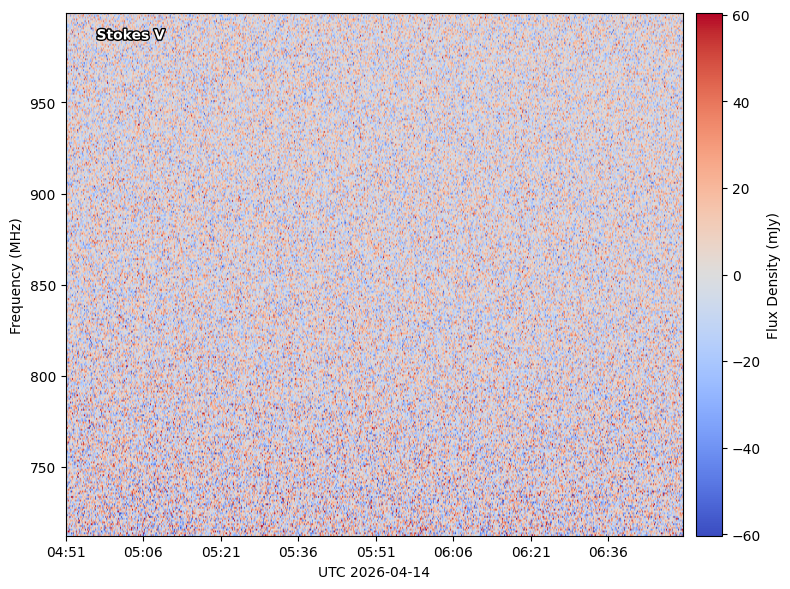

In [102]:
plot_ds(ds, stokes='V', cmax = 3*std_noise)

I'm not entirely sure that these errors are realistic. For now, lets assume we would see a burst if it is roughly the same signal strength as the noise (with some sustained pattern), and just try and modularly code our error function

In [42]:
def calculate_noise(ds): # RMS Noise
    return np.sqrt(np.nanmean(ds.data['V'].imag**2))

In [43]:
def calculate_threshold_luminosity(noise, distance): # What is the minimum burst luminosity we can detect?
    distance = distance * u.pc
    noise = noise * u.mJy
    return 4 * np.pi * distance**2 * noise

In [44]:
sfu = 1e-22 * u.W / u.m**2 / u.Hz
def calculate_sfu(luminosity):
    luminosity_at_sun = luminosity / (4 * np.pi * (1 * u.AU)**2)
    return luminosity_at_sun.to(sfu)

So let's see what sort of sfu's we would expect to see:

In [ ]:
for src in sources:

    # Get the Gaia ID
    source_name = src['Simbad_ID']
    folder_name = re.sub(r'[^a-z0-9_-]', '', source_name.lower().replace(" ", "_"))
    srsc_masked = srsc_id_table[srsc_id_table['Simbad_ID'] == source_name]
    gaia_id = str(srsc_masked['GaiaDR3_ID'][0]).lstrip('Gaia DR3 ')

    # Get the DS list
    matches = [p for p in ds_files if folder_name in str(p)]
    if len(matches) == 0:
        continue 
        
    # For each DS:
    for match in matches:
        ds_name = match.stem
        ds = DynamicSpectrum(ds_path=match)

        # Calculate a noise
        noise = calculate_noise(ds)

        # Calculate a distance
        if gaia_id == '--' and (folder_name == 'hd__52118'):
            dist = hd_52118_dist
        
        else:
            gaia_id = int(gaia_id)
            dist_table_masked = dist_data[dist_data['source_id'] == gaia_id]
            dist = dist_table_masked['r_med_geo'][0]

        # Calculate a luminosity
        threshold_luminosity = calculate_threshold_luminosity(noise, dist)

        # Find the equivelant SFU
        sfu_limit = calculate_sfu(threshold_luminosity)

        # Print out our results
        print(f'{ds_name}: SFU limit {sfu_limit:.2f} sfu, observation time: {np.max(ds.time):.2f} hrs')
    print()

# Calculating number of expected flares

So now we have both the expected SFU and the duration on source. Next, we just need to propagate the equation from Nita 2002, calculate a rate for N(>x sfu) per day/hour/whatever, and multiply by the observing time. Note that we are looking between two different frequency bands currently. 0.1-0.9, 1.0-1.7. I am going to use the 1.0 - 1.7 GHz band since it most closely matches ASKAP, but note that this isn't an exact solution.

In [45]:
def calculate_event_rate(sfu_limit, lam = -1.76):
    N_gr_1 = 148576
    hours = 14610 * 24
    return (N_gr_1 * sfu_limit**(lam + 1)) / hours

Now we just need to sub this all in, multiply by the observing time, and sum up all of our rates:

In [21]:
total_expected_count = 0
observing_duration = 0

for src in sources:

    # Get the Gaia ID
    source_name = src['Simbad_ID']
    folder_name = re.sub(r'[^a-z0-9_-]', '', source_name.lower().replace(" ", "_"))
    srsc_masked = srsc_id_table[srsc_id_table['Simbad_ID'] == source_name]
    gaia_id = str(srsc_masked['GaiaDR3_ID'][0]).lstrip('Gaia DR3 ')

    # Get the DS list
    matches = [p for p in ds_files if folder_name in str(p)]
    if len(matches) == 0:
        continue 
        
    # For each DS:
    for match in matches:
        ds_name = match.stem
        ds = DynamicSpectrum(ds_path=match)

        # Calculate a noise
        noise = calculate_noise(ds)

        # Calculate a distance
        if gaia_id == '--' and (folder_name == 'hd__52118'):
            dist = hd_52118_dist
        
        else:
            gaia_id = int(gaia_id)
            dist_table_masked = dist_data[dist_data['source_id'] == gaia_id]
            dist = dist_table_masked['r_med_geo'][0]

        # Calculate a luminosity
        threshold_luminosity = calculate_threshold_luminosity(noise, dist)

        # Find the equivelant SFU
        sfu_limit = calculate_sfu(threshold_luminosity)

        # Calculate expected number of flares
        expected_flares_per_hour = calculate_event_rate(sfu_limit.value)
        expected_flares = expected_flares_per_hour * np.max(ds.time)

        total_expected_count += expected_flares
        observing_duration += np.max(ds.time)

In [22]:
total_expected_count

np.float64(7.637394565025283e-05)

In [23]:
observing_duration

np.float64(738.5389056000276)

So after 700 hours, absoltely no shot of seeing a flare. To see a single flare (on average) we would have to wait:

In [24]:
(observing_duration / total_expected_count) / 24 / 365

np.float64(1103.8855401377236)

Over 1,100 sky years with ASKAP

There are a few assumptions we made here. Let's outline them and brainstorm some fixes:

1) We assumed all of our observations were between 1-1.7 GHz
2) We assumed RMS of imaginary visibility is our proxy for detection threshold

What about the sun itself? What is the highest SFU we have ever seen from it? Is it even close to what we would need to see these flares?

# Varying noise definitions

I want to see how binning affects our results. This means averaging our DS a number of times. The extreme is to also calculate our statistics from a lightcurve as well, so let's try that and see how our statistics change. I am still going to use the RMS, as it equivelant to the STD noise as shown above. Let's also just work with a subset of our data for ease of computation. Since the indices are random, we expect some VAST/RACS, some EMU etc, so hopefully a representative sample.



In [25]:
indices = np.random.choice(len(ds_files), size=50, replace=False)
ds_test_set = np.array(ds_files)[indices]

In [201]:
for src in sources:

    # Get the Gaia ID
    source_name = src['Simbad_ID']
    folder_name = re.sub(r'[^a-z0-9_-]', '', source_name.lower().replace(" ", "_"))
    srsc_masked = srsc_id_table[srsc_id_table['Simbad_ID'] == source_name]
    gaia_id = str(srsc_masked['GaiaDR3_ID'][0]).lstrip('Gaia DR3 ')

    # Get the DS list
    matches = [p for p in ds_test_set if folder_name in str(p)]
    if len(matches) == 0:
        continue 
        
    # For each DS:
    for match in matches:
        
        ds_name = match.stem
        temp_ds = DynamicSpectrum(ds_path=match)

        # Try a series of averaging
        for avg in [1,2,5,10,15,25,50,75,100]:

            # Go until it cant average anymore
            try:
                ds = DynamicSpectrum(ds_path=match, favg=avg, tavg=avg)
            
            except IndexError:
                break

            lc = LightCurve(ds)

            ds_noise = calculate_noise(ds) # RMS noise
            lc_noise = 5 * np.nanstd(lc.flux['V']) # 5 Sigma detection threshold

            print(f'{ds_name} (avg = {avg}) DS Noise {ds_noise:.2f} LC Noise {lc_noise:.2f}')
        
        print()

hd102982_racs_1143_51 (avg = 1) DS Noise 16.13 LC Noise 7.00
hd102982_racs_1143_51 (avg = 2) DS Noise 7.12 LC Noise 4.53
hd102982_racs_1143_51 (avg = 5) DS Noise 3.01 LC Noise 2.93
hd102982_racs_1143_51 (avg = 10) DS Noise 1.63 LC Noise 2.20
hd102982_racs_1143_51 (avg = 15) DS Noise 1.07 LC Noise 1.46
hd102982_racs_1143_51 (avg = 25) DS Noise 0.57 LC Noise 0.77

hd102982_wallaby_1142_53a (avg = 1) DS Noise 24.44 LC Noise 9.68
hd102982_wallaby_1142_53a (avg = 2) DS Noise 13.29 LC Noise 7.26
hd102982_wallaby_1142_53a (avg = 5) DS Noise 7.28 LC Noise 5.63
hd102982_wallaby_1142_53a (avg = 10) DS Noise 3.84 LC Noise 5.14
hd102982_wallaby_1142_53a (avg = 15) DS Noise 2.14 LC Noise 4.22
hd102982_wallaby_1142_53a (avg = 25) DS Noise 1.19 LC Noise 3.19
hd102982_wallaby_1142_53a (avg = 50) DS Noise 0.55 LC Noise 2.15

hd82533_emu_0932_51 (avg = 1) DS Noise 21.57 LC Noise 6.67
hd82533_emu_0932_51 (avg = 2) DS Noise 10.88 LC Noise 4.93
hd82533_emu_0932_51 (avg = 5) DS Noise 4.31 LC Noise 3.43
hd82

So our noise level does decrease rapidly as we allow for averaging. The sensible next question is what is the correct amount of averaging? This is especially important when we consider that we want to be able to detect rapid bursts as well. Sometimes a flare may only be bright on the order of seconds-minutes, so averaging at a high level could completely flatten/erase this flare from the DS.

# The Largest Solar Burst

From Extreme Solar Events: sec 4.2. Dec 2006 burst reached ~$10^6$ sfu. This is, to date, the most energetic flare recorded in radio frequencies. Would we have seen this? First, let's see the minimum SFU limit we have without averaging.

In [208]:
min_sfu_limit = 1e10

for src in sources:

    # Get the Gaia ID
    source_name = src['Simbad_ID']
    folder_name = re.sub(r'[^a-z0-9_-]', '', source_name.lower().replace(" ", "_"))
    srsc_masked = srsc_id_table[srsc_id_table['Simbad_ID'] == source_name]
    gaia_id = str(srsc_masked['GaiaDR3_ID'][0]).lstrip('Gaia DR3 ')

    # Get the DS list
    matches = [p for p in ds_files if folder_name in str(p)]
    if len(matches) == 0:
        continue 
        
    # For each DS:
    for match in matches:
        ds_name = match.stem
        ds = DynamicSpectrum(ds_path=match)

        # Calculate a noise
        noise = calculate_noise(ds)

        # Calculate a distance
        if gaia_id == '--' and (folder_name == 'hd__52118'):
            dist = hd_52118_dist
        
        else:
            gaia_id = int(gaia_id)
            dist_table_masked = dist_data[dist_data['source_id'] == gaia_id]
            dist = dist_table_masked['r_med_geo'][0]

        # Calculate a luminosity
        threshold_luminosity = calculate_threshold_luminosity(noise, dist)

        # Find the equivelant SFU
        sfu_limit = calculate_sfu(threshold_luminosity)

        if sfu_limit.value < min_sfu_limit:
            min_sfu_limit = sfu_limit.value

print(f"{min_sfu_limit:.2e}")

1.50e+08


The answer to that is no.

What if we gave it our best go. The burst peak lasted around 10 mins (Effect of intense December 2006 solar radio bursts on GPS receivers). If each time bin is 10s, then lets set t_avg to be 50. Let's also place it at the distance of the nearest star, and give it the noise level of our best DS.

In [46]:
min_dist = 1000

for src in sources:

    # Get the Gaia ID
    source_name = src['Simbad_ID']
    folder_name = re.sub(r'[^a-z0-9_-]', '', source_name.lower().replace(" ", "_"))
    srsc_masked = srsc_id_table[srsc_id_table['Simbad_ID'] == source_name]
    gaia_id = str(srsc_masked['GaiaDR3_ID'][0]).lstrip('Gaia DR3 ')

    # Get the DS list
    matches = [p for p in ds_files if folder_name in str(p)]
    if len(matches) == 0:
        continue 

    # Calculate a distance
    if gaia_id == '--' and (folder_name == 'hd__52118'):
        dist = hd_52118_dist
    
    else:
        gaia_id = int(gaia_id)
        dist_table_masked = dist_data[dist_data['source_id'] == gaia_id]
        dist = dist_table_masked['r_med_geo'][0]

    if dist < min_dist:
        min_dist = dist

print(f'Nearest star: {min_dist:.2f} pc')

Nearest star: 45.25 pc


In [56]:
min_noise = 9999

for src in sources:

    # Get the Gaia ID
    source_name = src['Simbad_ID']
    folder_name = re.sub(r'[^a-z0-9_-]', '', source_name.lower().replace(" ", "_"))
    srsc_masked = srsc_id_table[srsc_id_table['Simbad_ID'] == source_name]
    gaia_id = str(srsc_masked['GaiaDR3_ID'][0]).lstrip('Gaia DR3 ')

    # Get the DS list
    matches = [p for p in ds_files if folder_name in str(p)]
    if len(matches) == 0:
        continue 
        
    # For each DS:
    for match in matches:
        ds_name = match.stem
        
        try:
            ds = DynamicSpectrum(ds_path=match, tavg=60, favg=5)
        except IndexError:
            break

        # Calculate a noise
        noise = calculate_noise(ds)

        if noise < min_noise:
            min_noise = noise

print(f'Lowest noise: {min_noise:.2f} mJy')

Lowest noise: 0.53 mJy


Now we can calculate what our best case scenario would be in terms of our sfu sensitivity

In [57]:
# Calculate a luminosity
threshold_luminosity = calculate_threshold_luminosity(min_noise, min_dist)

# Find the equivelant SFU
sfu_limit = calculate_sfu(threshold_luminosity)

print(f'Best case detection limit: {sfu_limit.value:.2e} sfu')

Best case detection limit: 4.58e+06 sfu


So, assuming everything went perfectly, we could detect this one burst. Is this realistic? No. But good to know that, given perfect conditions, this is possible.

# Thesis plotting code

In [26]:
avgs = [1, 2, 5, 10, 15, 25, 50, 75, 100]

# Store noise measurements for each averaging bin
ds_noise_data = {avg: [] for avg in avgs}
lc_noise_data = {avg: [] for avg in avgs}

for src in sources:

    # Get the Gaia ID
    source_name = src['Simbad_ID']
    folder_name = re.sub(r'[^a-z0-9_-]', '', source_name.lower().replace(" ", "_"))
    srsc_masked = srsc_id_table[srsc_id_table['Simbad_ID'] == source_name]
    gaia_id = str(srsc_masked['GaiaDR3_ID'][0]).lstrip('Gaia DR3 ')

    # Get the DS list
    matches = [p for p in ds_test_set if folder_name in str(p)]
    if len(matches) == 0:
        continue

    # For each DS
    for match in matches:

        ds_name = match.stem

        # Try each averaging bin
        for avg in avgs:

            try:
                ds = DynamicSpectrum(ds_path=match, favg=avg, tavg=avg)
            except IndexError:
                break

            lc = LightCurve(ds)

            ds_noise = calculate_noise(ds)
            lc_noise = 5 * np.nanstd(lc.flux['V'])

            # Append measurements to the relevant averaging bin
            ds_noise_data[avg].append(ds_noise)
            lc_noise_data[avg].append(lc_noise)

            print(
                f'{ds_name} (avg = {avg}) '
                f'DS Noise {ds_noise:.2f} '
                f'LC Noise {lc_noise:.2f}'
            )

        print()

hd102982_wallaby_1142_53a (avg = 1) DS Noise 24.44 LC Noise 9.68
hd102982_wallaby_1142_53a (avg = 2) DS Noise 13.29 LC Noise 7.26
hd102982_wallaby_1142_53a (avg = 5) DS Noise 7.28 LC Noise 5.63
hd102982_wallaby_1142_53a (avg = 10) DS Noise 3.84 LC Noise 5.14
hd102982_wallaby_1142_53a (avg = 15) DS Noise 2.14 LC Noise 4.22
hd102982_wallaby_1142_53a (avg = 25) DS Noise 1.19 LC Noise 3.19
hd102982_wallaby_1142_53a (avg = 50) DS Noise 0.55 LC Noise 2.15

hd82533_emu_0917_55 (avg = 1) DS Noise 20.40 LC Noise 6.11
hd82533_emu_0917_55 (avg = 2) DS Noise 10.15 LC Noise 4.30
hd82533_emu_0917_55 (avg = 5) DS Noise 3.75 LC Noise 2.57
hd82533_emu_0917_55 (avg = 10) DS Noise 1.92 LC Noise 1.82
hd82533_emu_0917_55 (avg = 15) DS Noise 1.29 LC Noise 1.58
hd82533_emu_0917_55 (avg = 25) DS Noise 0.77 LC Noise 1.33
hd82533_emu_0917_55 (avg = 50) DS Noise 0.38 LC Noise 1.05
hd82533_emu_0917_55 (avg = 75) DS Noise 0.24 LC Noise 0.95
hd82533_emu_0917_55 (avg = 100) DS Noise 0.18 LC Noise 0.88

hd82533_emu_0

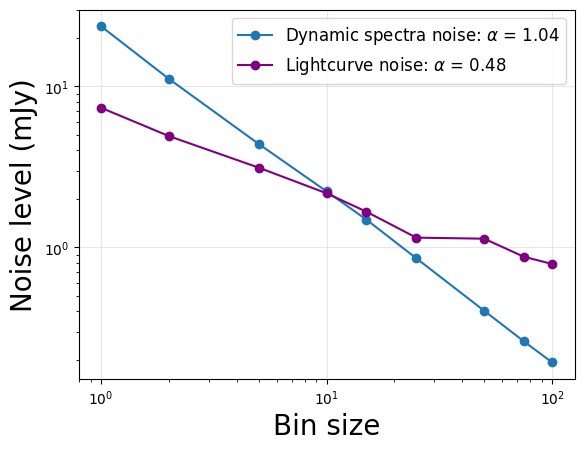

In [62]:
ds_mean = [np.nanmean(ds_noise_data[avg]) for avg in avgs]
lc_mean = [np.nanmean(lc_noise_data[avg]) for avg in avgs]

plt.plot(avgs, ds_mean, 'o-', label=r'Dynamic spectra noise: $\alpha$ = 1.04')
plt.plot(avgs, lc_mean, 'o-', label=r'Lightcurve noise: $\alpha$ = 0.48', color = 'purple')
plt.xlabel('Bin size', fontsize=20)
plt.ylabel('Noise level (mJy)', fontsize=20)
# plt.title('Effects of averaging on RMS noise levels')
plt.xscale('log')
plt.yscale('log')
plt.legend(fontsize=12)
plt.grid(True, alpha=0.3)

plt.savefig('thesis_figs/rms-noise-averaging.pdf', dpi=300)
plt.show()

In [29]:
from scipy.stats import linregress

avgs = np.array(avgs)

ds_mean = np.array([
    np.nanmean(lc_noise_data[avg]) for avg in avgs
])

valid = np.isfinite(ds_mean) & (ds_mean > 0)

fit = linregress(
    np.log10(avgs[valid]),
    np.log10(ds_mean[valid])
)

alpha = -fit.slope

print(f"Noise ∝ avg^(-{alpha:.2f})")
print(f"R² = {fit.rvalue**2:.3f}")

Noise ∝ avg^(-0.48)
R² = 0.983
